In [43]:
import numpy as np
import pandas as pd

In [ ]:
'''
stage_1_rank1:
graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.5/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs64_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'
##################
stage_2_rank1:
graph_path_1 = './result/w_layer/stage2/tuning/bs64_dp0.3_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'
#################
stage_3_rank1:
graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'


'''

## stage1

In [1]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.5/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs64_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name #.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)


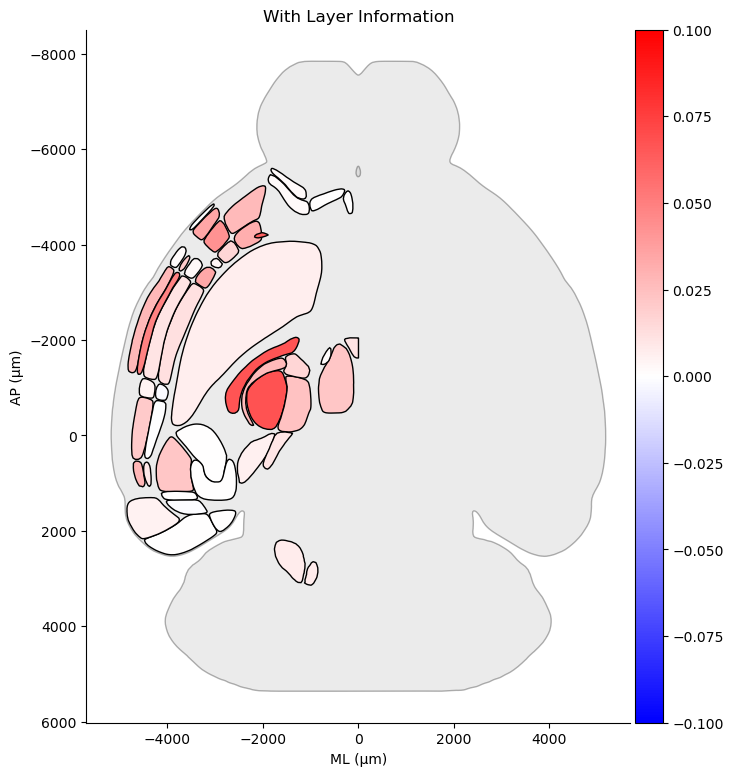

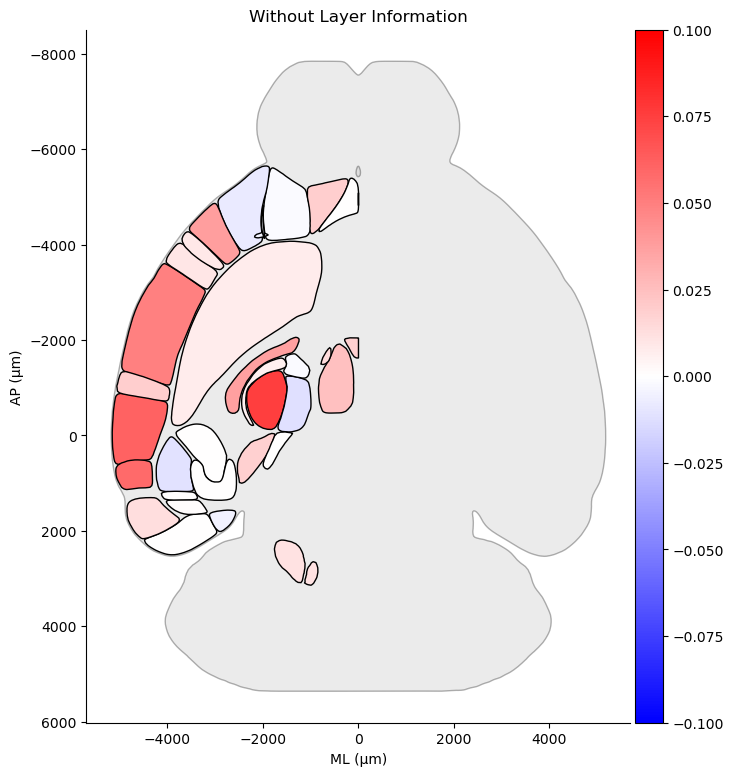

In [2]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

# 假设 mean_dc_1 和 mean_dc_2 已计算完毕
values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

# 第一张：含分层信息
fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

# 第二张：不含分层信息
fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')


r = 0.368, p = 6.586e-04, MAE = 0.0126


/tmp/ipykernel_404884/2594352976.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


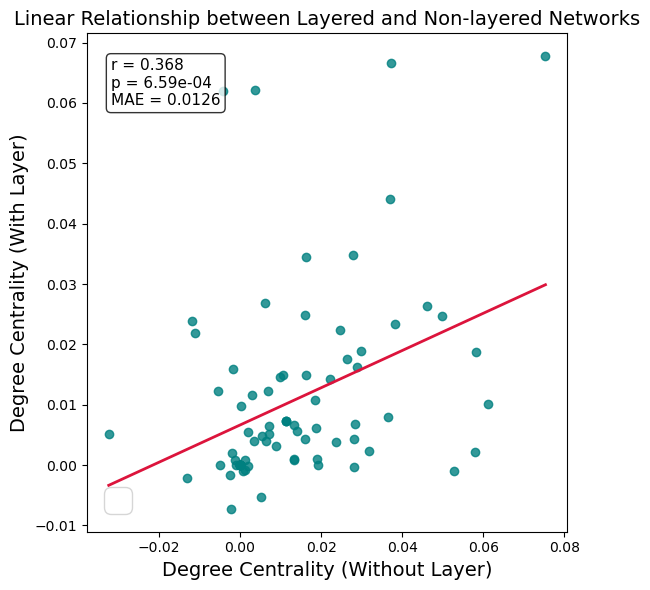

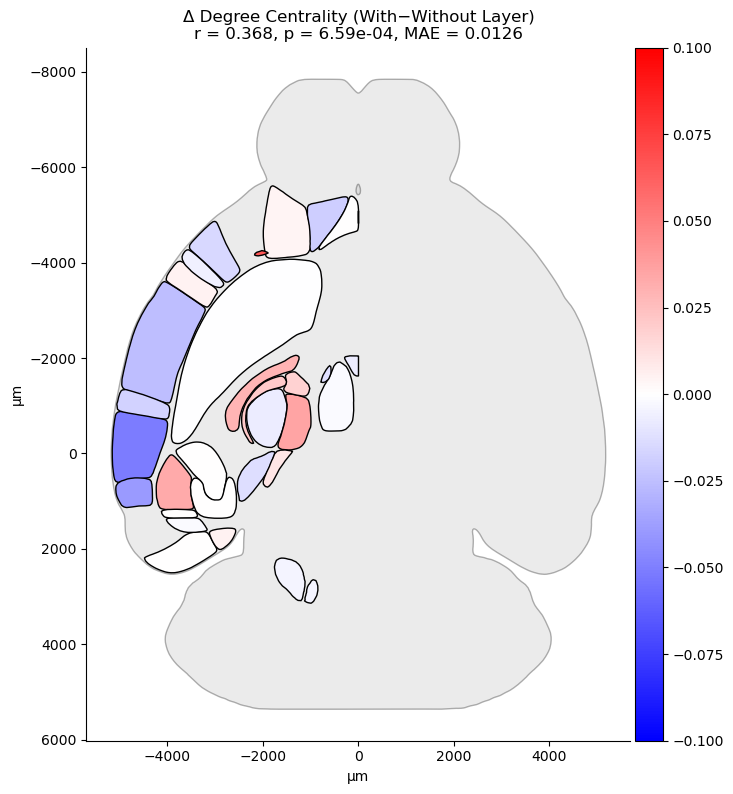

In [3]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/rank2_scatter_with_vs_without_layer_stage1.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)

## stage2

In [4]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage2/tuning/bs64_dp0.3_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)

#print("✅ 组1（含分层）主要脑区中心性：")
#print(mean_dc_1.head())
#print("\n✅ 组2（不含分层）主要脑区中心性：")
#print(mean_dc_2.head())


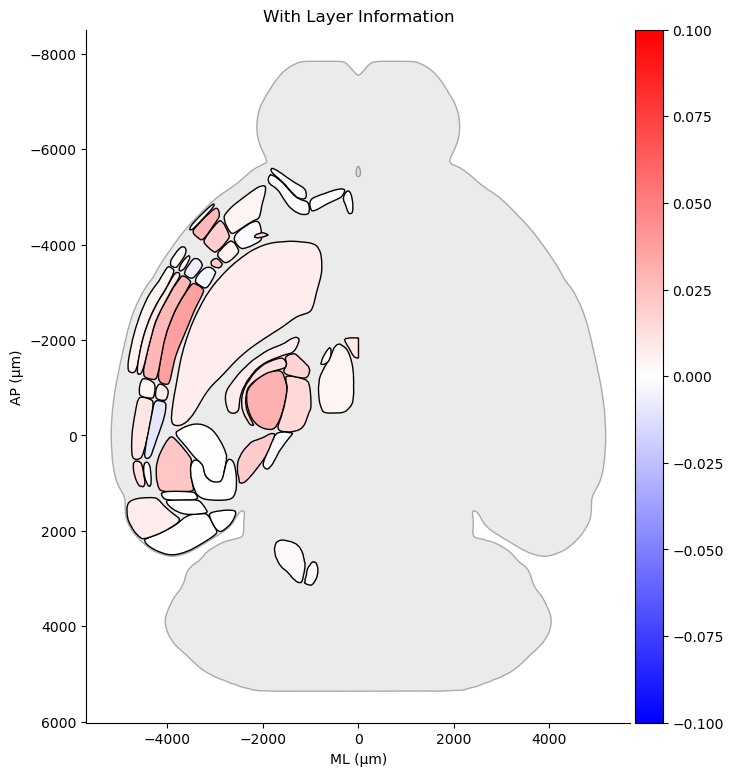

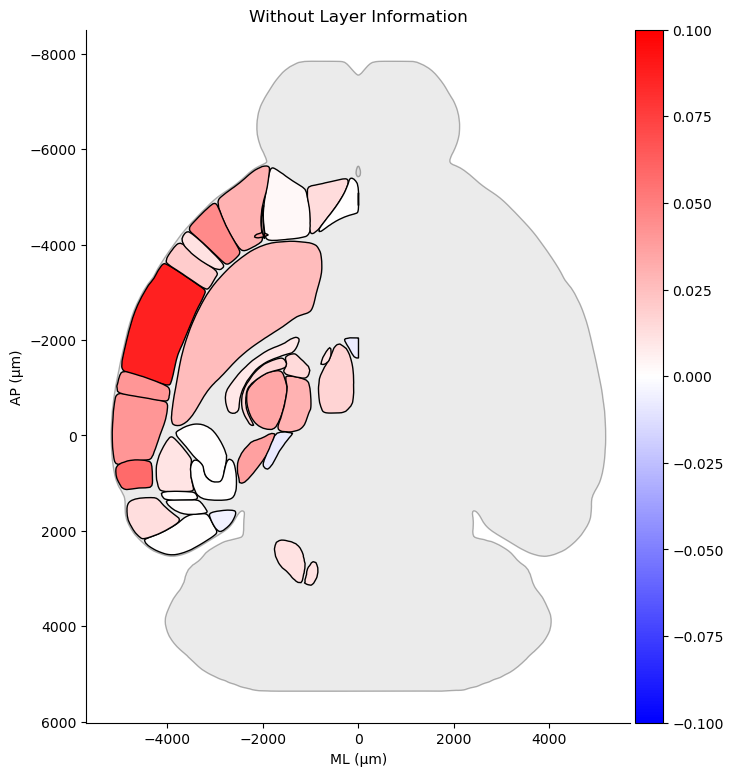

In [5]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

# 假设 mean_dc_1 和 mean_dc_2 已计算完毕
values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

# 第一张：含分层信息
fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

# 第二张：不含分层信息
fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')


r = 0.603, p = 2.088e-09, MAE = 0.0134


/tmp/ipykernel_404884/1977614740.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


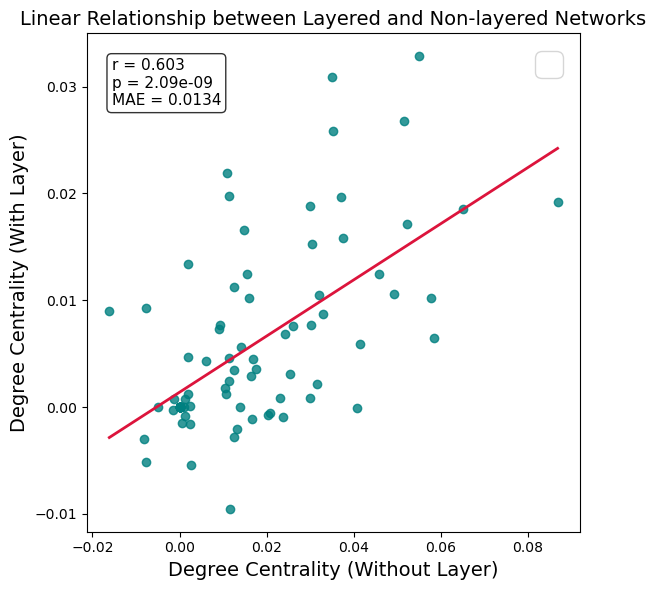

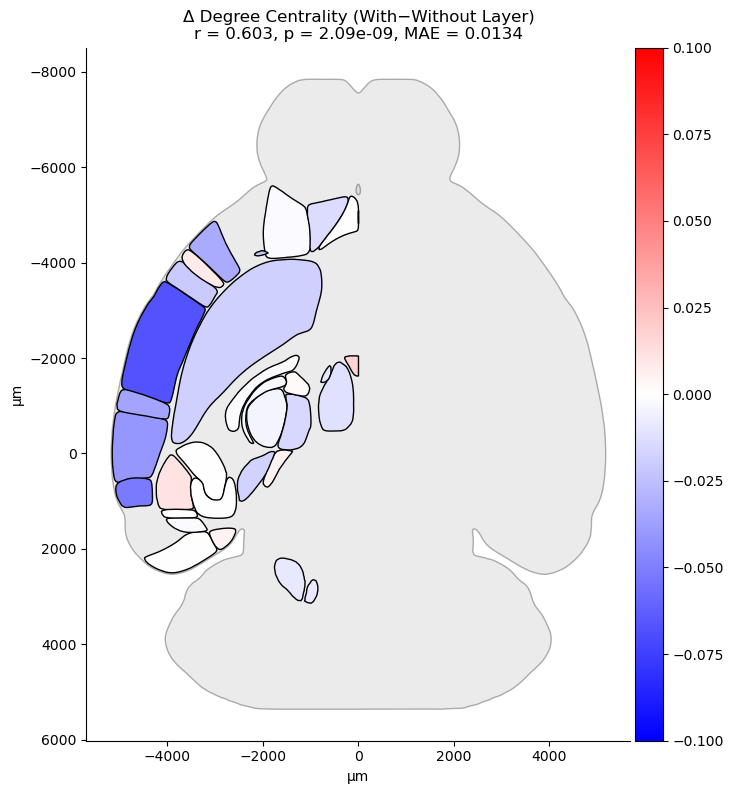

In [6]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/rank2_scatter_with_vs_without_layer_stage2.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)

## stage3

In [7]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)


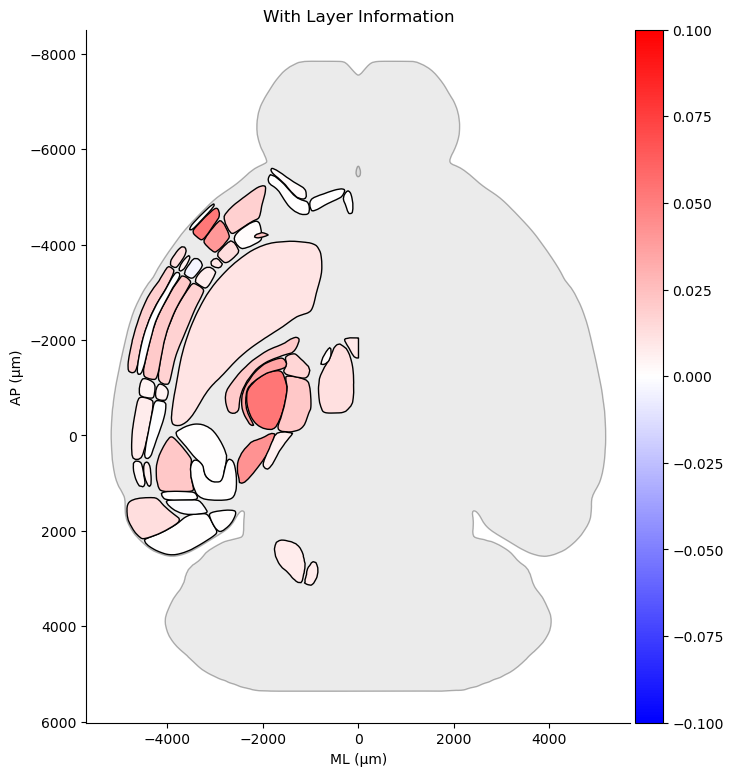

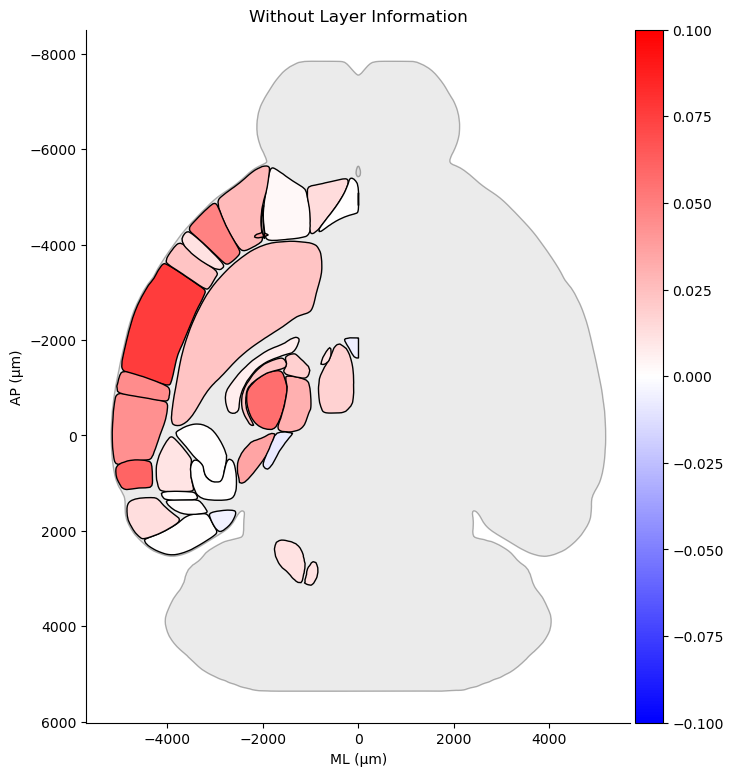

In [8]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

# 假设 mean_dc_1 和 mean_dc_2 已计算完毕
values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

# 第一张：含分层信息
fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

# 第二张：不含分层信息
fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')


r = 0.485, p = 3.908e-06, MAE = 0.0126


/tmp/ipykernel_404884/1386256871.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


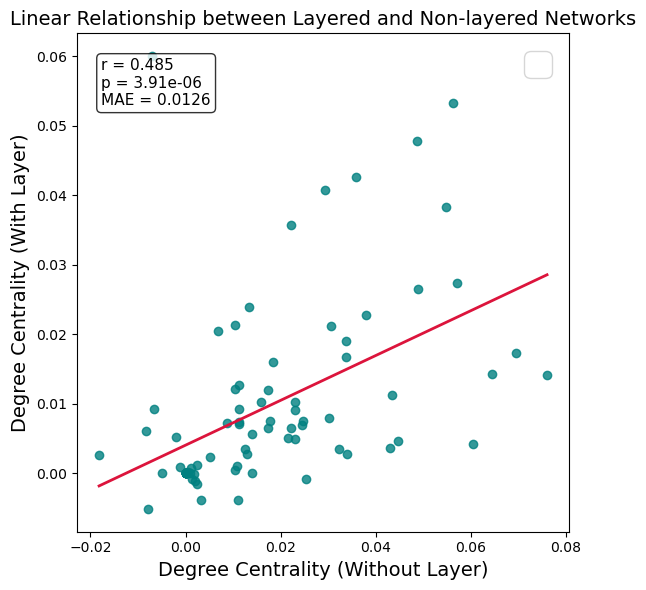

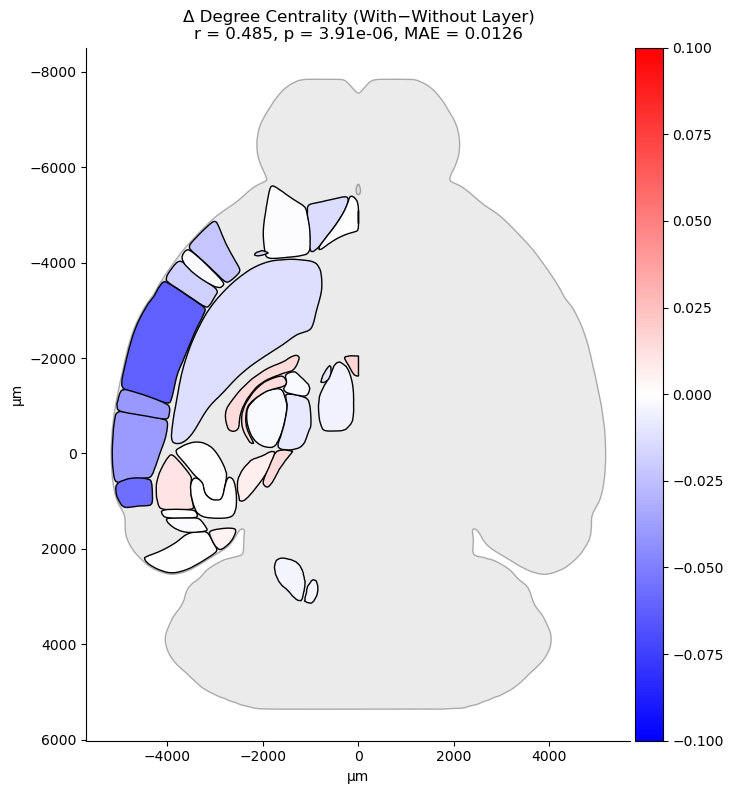

In [9]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/rank2_scatter_with_vs_without_layer_stage3.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)